# 01. Data Understanding — Dunnhumby Dataset

**Mục tiêu**: Đánh giá tổng quan chất lượng dữ liệu, phân tích lịch sử mua sắm của household và kiểm tra tính khả thi cho bài toán Propensity Modeling.

*Lưu ý*: `DAY` trong Dunnhumby là chỉ số ngày tương đối; notebook quy đổi sang mốc ngày giả định (`2000-01-01`) để phân tích chuỗi thời gian.

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import polars as pl

# Tự động tìm project root (chứa thư mục src) dù notebook ở thư mục gốc hay trong thư mục notebooks/
project_root = Path.cwd().resolve()
while project_root.parent != project_root and not (project_root / "src").exists():
    project_root = project_root.parent

if not (project_root / "src").exists():
    raise RuntimeError("Không tìm thấy project root chứa thư mục src")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.eda.contracts import DatasetSpec
from src.eda.descriptive import (
    describe_dataset,
    describe_entities,
    describe_quality,
    describe_temporal,
)
from src.eda.visualization import (
    plot_active_periods_per_entity,
    plot_entity_time_matrix,
    plot_missing_values,
    plot_records_over_time,
    plot_records_per_entity,
)

# Đường dẫn đến dữ liệu raw của Dunnhumby
data_dir = project_root / "data" / "raw" / "Dunnhumby"
if not data_dir.exists():
    raise FileNotFoundError(f"Không tìm thấy thư mục dữ liệu: {data_dir}")

pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(20)


def scalar_metrics(report):
    return {key: value for key, value in report.items() if not isinstance(value, pl.DataFrame)}


## 1. Load và chuẩn hóa bảng sự kiện

In [3]:
from datetime import date

transaction_lines = (
    pl.scan_csv(data_dir / "transaction_data.csv")
    .with_columns(
        (
            pl.lit(date(2000, 1, 1))
            + pl.duration(days=pl.col("DAY"))
        ).alias("event_date")
    )
)
basket_events = transaction_lines.select(
    "household_key", "BASKET_ID", "event_date"
).unique(subset=["BASKET_ID"])
spec = DatasetSpec(
    name="dunnhumby_baskets",
    entity_col="household_key",
    time_col="event_date",
    id_cols=("BASKET_ID",),
)

## 2. Dataset overview

In [4]:
dataset_report = describe_dataset(basket_events, spec)
print("Shape:", dataset_report["n_rows"], "rows x", dataset_report["n_cols"], "columns")
print("Dtype groups:", dataset_report["dtype_groups"])
display(dataset_report["overview"].sort("missing_frac", descending=True))
display(dataset_report["preview"])

Shape: 276484 rows x 3 columns
Dtype groups: {'numeric': ['household_key', 'BASKET_ID'], 'string': [], 'categorical': [], 'temporal': ['event_date'], 'boolean': [], 'other': []}


column,dtype,n_missing,missing_frac,n_unique_approx
str,str,i64,f64,i64
"""household_key""","""Int64""",0,0.0,2448
"""BASKET_ID""","""Int64""",0,0.0,276565
"""event_date""","""Date""",0,0.0,682


household_key,BASKET_ID,event_date
i64,i64,date
1350,29034419794,2000-06-05
1314,29034560196,2000-06-05
1197,29034665158,2000-06-05
52,29034663500,2000-06-05
147,29034805637,2000-06-05


## 3. Data quality

In [5]:
quality_report = describe_quality(basket_events, spec)
print(scalar_metrics(quality_report))
display(quality_report["column_quality"].sort("missing_pct", descending=True))

{'n_rows': 276484, 'n_cols': 3, 'n_duplicate_rows': 0, 'duplicate_row_pct': 0.0, 'n_missing_cells': 0, 'missing_cell_pct': 0.0, 'n_columns_with_missing': 0, 'constant_columns': [], 'all_missing_columns': []}


column,dtype,n_missing,missing_pct,n_unique_non_missing,is_constant,is_all_missing
str,str,i64,f64,i64,bool,bool
"""household_key""","""Int64""",0,0.0,2500,false,false
"""BASKET_ID""","""Int64""",0,0.0,276484,false,false
"""event_date""","""Date""",0,0.0,711,false,false


## 4. Temporal coverage

{'time_col': 'event_date', 'n_records': 276484, 'n_valid_time': 276484, 'n_missing_or_invalid_time': 0, 'start_date': datetime.date(2000, 1, 2), 'end_date': datetime.date(2001, 12, 12), 'history_months': 24, 'observed_months': 24, 'missing_months': [], 'mean_records_per_month': 11520.166666666666, 'std_records_per_month': 3199.026019309975, 'monthly_count_cv': 0.2776892133484737, 'min_records_per_month': 1897, 'max_records_per_month': 13651}


month,n_records
date,u32
2000-01-01,1897
2000-02-01,4101
2000-03-01,8221
2000-04-01,12013
2000-05-01,13479
2000-06-01,12894
2000-07-01,12659
2000-08-01,12854
2000-09-01,12611


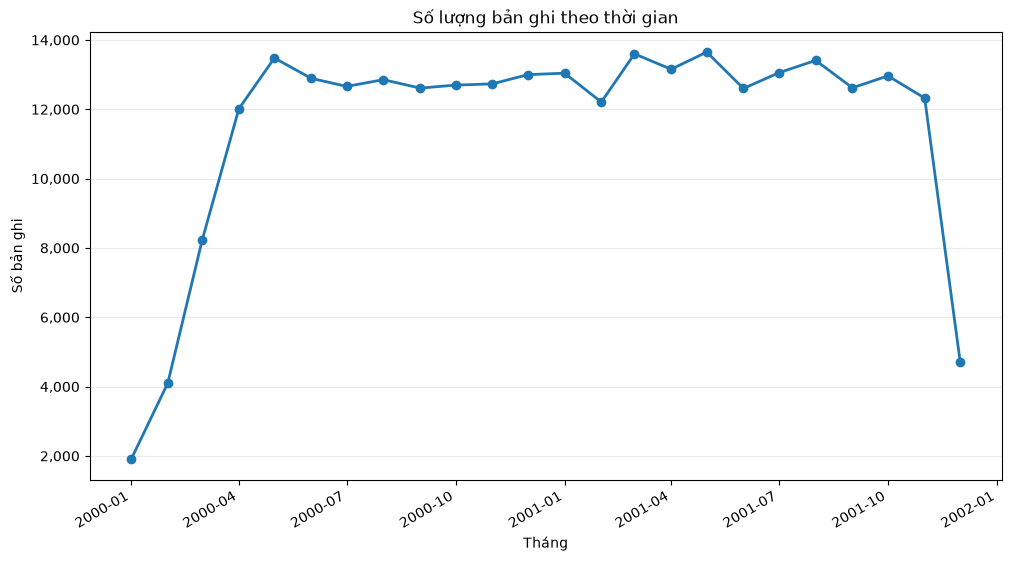

In [6]:
temporal_report = describe_temporal(basket_events, spec)
print(scalar_metrics(temporal_report))
display(temporal_report["monthly_records"])

plot_records_over_time(temporal_report["monthly_records"])
plt.show()

## 5. Entity history

{'entity_col': 'household_key', 'n_unique_entities': 2500, 'n_records_missing_entity': 0, 'n_repeat_entities': 2497, 'repeat_entity_pct': 99.88, 'avg_records_per_entity': 110.5936, 'n_entities_active_2plus_months': 2494, 'active_2plus_months_pct': 99.76, 'min_history_days': 0, 'min_history_days_gt_0': 9, 'mean_history_days': 619.4848, 'median_history_days': 626.0, 'max_history_days': 710}


household_key,n_records,n_active_months,first_seen,last_seen,history_days
i64,u32,u32,date,date,i64
1,86,23,2000-02-21,2001-12-07,655
2,45,17,2000-04-13,2001-10-30,565
3,47,19,2000-04-23,2001-12-04,590
4,30,15,2000-04-14,2001-09-19,523
5,40,17,2000-03-26,2001-12-04,618
6,250,21,2000-04-28,2001-12-08,589
7,59,22,2000-01-24,2001-12-10,686
8,113,22,2000-03-06,2001-12-07,641
9,20,13,2000-04-14,2001-11-20,585


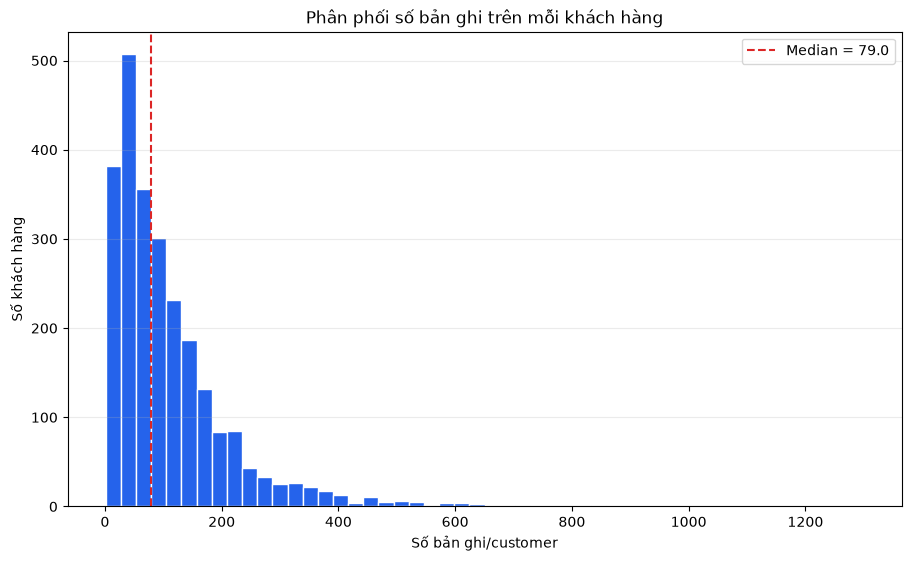

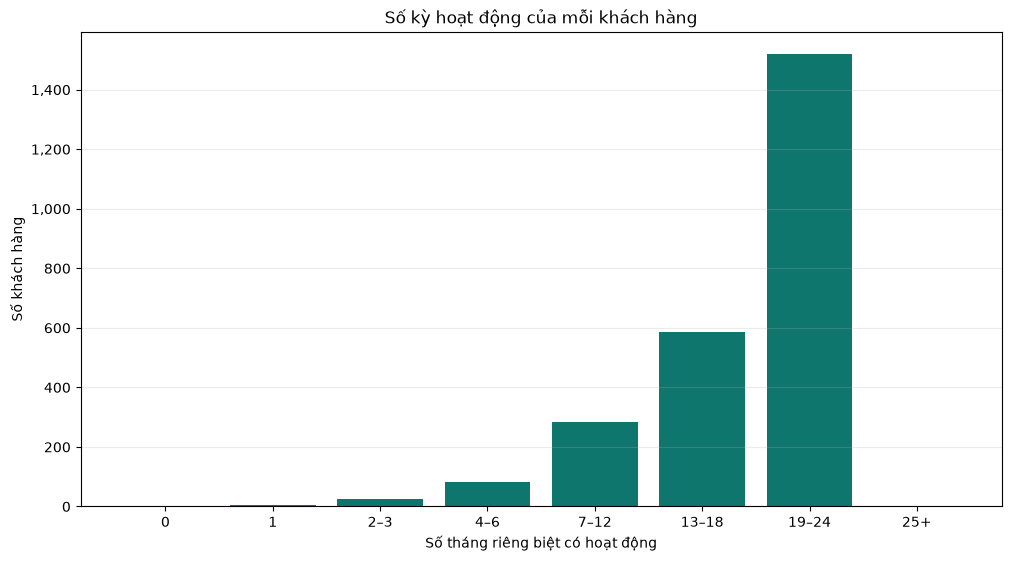

In [7]:
entity_report = describe_entities(basket_events, spec)
print(scalar_metrics(entity_report))
display(entity_report["entity_history"].head(20))

plot_records_per_entity(entity_report["entity_history"])
plt.show()
plot_active_periods_per_entity(entity_report["entity_history"])
plt.show()

## 6. Missing values

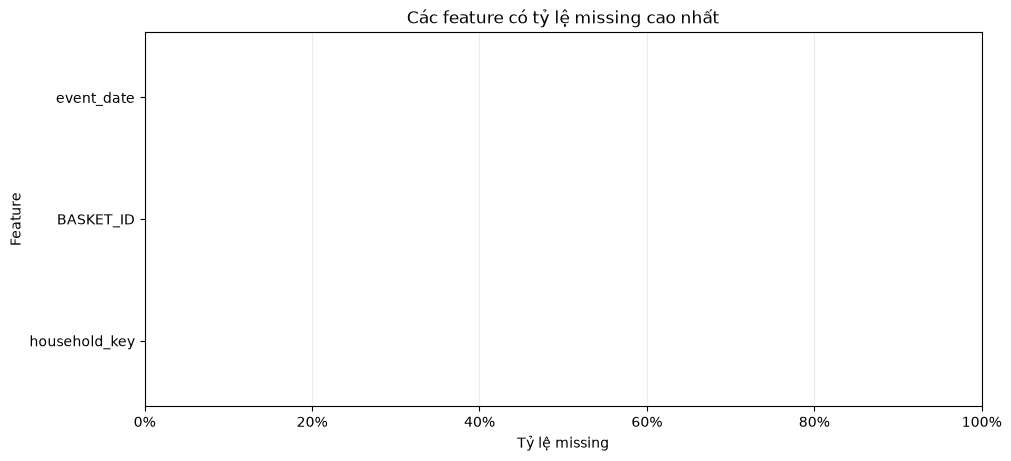

In [8]:
plot_missing_values(quality_report["column_quality"], top_n=20)
plt.show()

## 7. Customer activity matrix

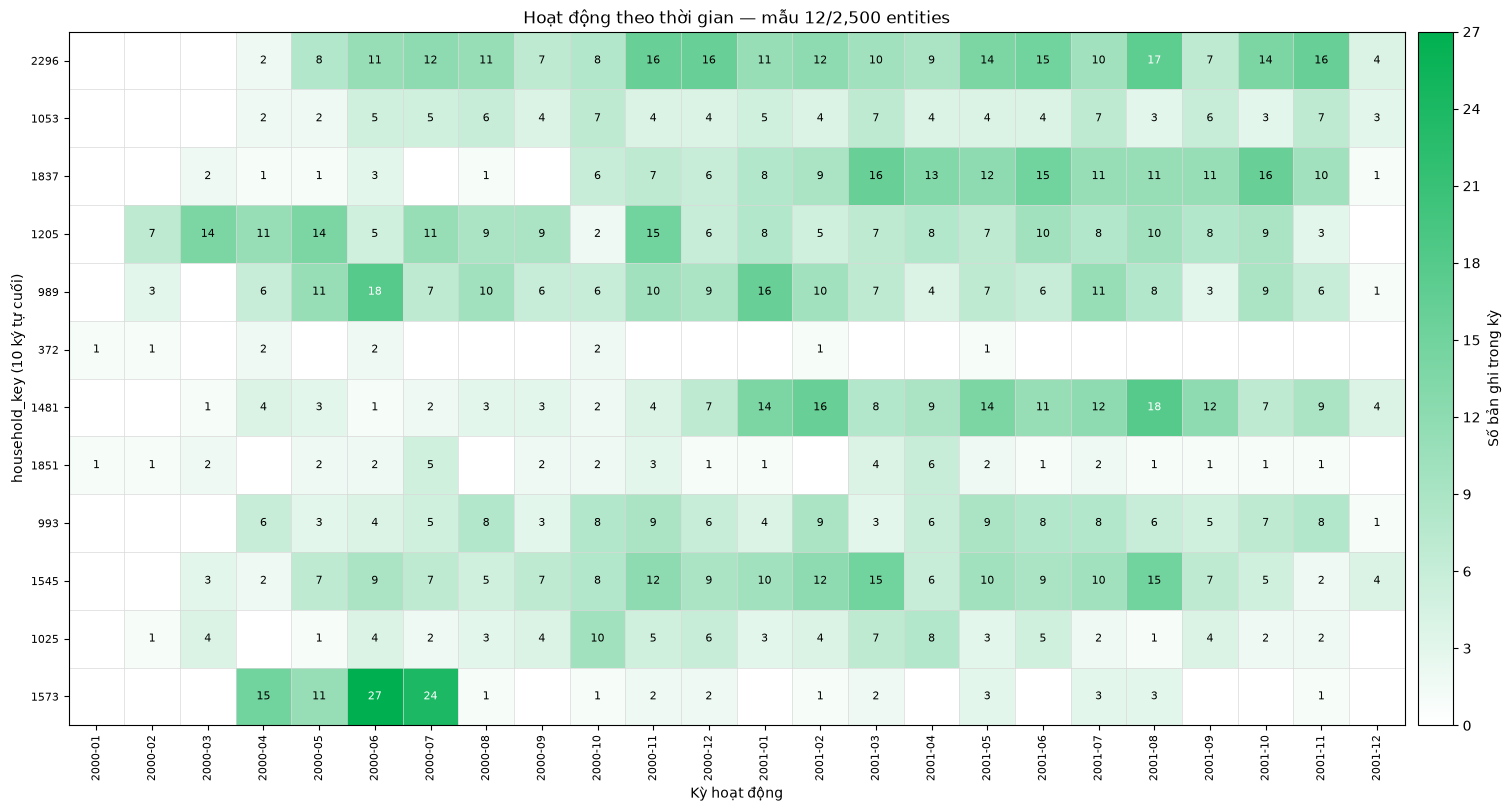

household_key,2000-01,2000-02,2000-03,2000-04,2000-05,2000-06,2000-07,2000-08,2000-09,…,2001-03,2001-04,2001-05,2001-06,2001-07,2001-08,2001-09,2001-10,2001-11,2001-12
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,…,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
2296,0,0,0,2,8,11,12,11,7,…,10,9,14,15,10,17,7,14,16,4
1053,0,0,0,2,2,5,5,6,4,…,7,4,4,4,7,3,6,3,7,3
1837,0,0,2,1,1,3,0,1,0,…,16,13,12,15,11,11,11,16,10,1
1205,0,7,14,11,14,5,11,9,9,…,7,8,7,10,8,10,8,9,3,0
989,0,3,0,6,11,18,7,10,6,…,7,4,7,6,11,8,3,9,6,1
372,1,1,0,2,0,2,0,0,0,…,0,0,1,0,0,0,0,0,0,0
1481,0,0,1,4,3,1,2,3,3,…,8,9,14,11,12,18,12,7,9,4
1851,1,1,2,0,2,2,5,0,2,…,4,6,2,1,2,1,1,1,1,0
993,0,0,0,6,3,4,5,8,3,…,3,6,9,8,8,6,5,7,8,1


household_key,active_periods,total_periods,coverage_pct,total_records
i64,u32,i32,f64,u32
1053,21,24,87.5,96
989,22,24,91.666667,174
1573,14,24,58.333333,96
2296,21,24,87.5,230
1545,22,24,91.666667,174
1837,20,24,83.333333,160
993,21,24,87.5,126
1481,22,24,91.666667,164
1205,22,24,91.666667,186


Global coverage: ActivityCoverage(n_entities=2500, n_eligible_entities=2494, n_periods=24, n_active_entity_periods=45264, coverage_pct=75.44, sample_size=12)


In [9]:
matrix_result = plot_entity_time_matrix(
    basket_events,
    entity_col=spec.entity_col,
    timestamp_col=spec.time_col,
    sample_size=12,
    min_active_periods=2,
    seed=42,
    id_suffix=10,
    annotate=True,
    unique_col="BASKET_ID",
)
plt.show()
display(matrix_result.matrix)
display(matrix_result.entity_coverage)
print("Global coverage:", matrix_result.global_coverage)

## 8. Dataset-specific signals

In [10]:
transaction_summary = transaction_lines.select(
    pl.len().alias("n_product_lines"),
    pl.col("BASKET_ID").n_unique().alias("n_baskets"),
    pl.col("household_key").n_unique().alias("n_households"),
    pl.col("SALES_VALUE").sum().alias("total_sales"),
    pl.col("QUANTITY").sum().alias("total_quantity"),
).collect()
display(transaction_summary)

demographics = pl.scan_csv(data_dir / "hh_demographic.csv")
print("Demographic schema:", demographics.collect_schema())
display(demographics.head(10).collect())

supporting_files = [
    "campaign_desc.csv", "campaign_table.csv", "coupon_redempt.csv",
    "coupon.csv", "product.csv", "causal_data.csv",
]
for filename in supporting_files:
    table = pl.scan_csv(data_dir / filename)
    print(filename, table.collect_schema())

n_product_lines,n_baskets,n_households,total_sales,total_quantity
u32,u32,u32,f64,i64
2595732,276484,2500,8.0575e6,260685622


Demographic schema: Schema([('AGE_DESC', String), ('MARITAL_STATUS_CODE', String), ('INCOME_DESC', String), ('HOMEOWNER_DESC', String), ('HH_COMP_DESC', String), ('HOUSEHOLD_SIZE_DESC', String), ('KID_CATEGORY_DESC', String), ('household_key', Int64)])


AGE_DESC,MARITAL_STATUS_CODE,INCOME_DESC,HOMEOWNER_DESC,HH_COMP_DESC,HOUSEHOLD_SIZE_DESC,KID_CATEGORY_DESC,household_key
str,str,str,str,str,str,str,i64
"""65+""","""A""","""35-49K""","""Homeowner""","""2 Adults No Kids""","""2""","""None/Unknown""",1
"""45-54""","""A""","""50-74K""","""Homeowner""","""2 Adults No Kids""","""2""","""None/Unknown""",7
"""25-34""","""U""","""25-34K""","""Unknown""","""2 Adults Kids""","""3""","""1""",8
"""25-34""","""U""","""75-99K""","""Homeowner""","""2 Adults Kids""","""4""","""2""",13
"""45-54""","""B""","""50-74K""","""Homeowner""","""Single Female""","""1""","""None/Unknown""",16
"""65+""","""B""","""Under 15K""","""Homeowner""","""2 Adults No Kids""","""2""","""None/Unknown""",17
"""45-54""","""A""","""100-124K""","""Homeowner""","""2 Adults No Kids""","""2""","""None/Unknown""",18
"""35-44""","""B""","""15-24K""","""Unknown""","""Single Female""","""1""","""None/Unknown""",19
"""25-34""","""A""","""75-99K""","""Renter""","""2 Adults No Kids""","""2""","""None/Unknown""",20


campaign_desc.csv Schema([('DESCRIPTION', String), ('CAMPAIGN', Int64), ('START_DAY', Int64), ('END_DAY', Int64)])
campaign_table.csv Schema([('DESCRIPTION', String), ('household_key', Int64), ('CAMPAIGN', Int64)])
coupon_redempt.csv Schema([('household_key', Int64), ('DAY', Int64), ('COUPON_UPC', Int64), ('CAMPAIGN', Int64)])
coupon.csv Schema([('COUPON_UPC', Int64), ('PRODUCT_ID', Int64), ('CAMPAIGN', Int64)])
product.csv Schema([('PRODUCT_ID', Int64), ('MANUFACTURER', Int64), ('DEPARTMENT', String), ('BRAND', String), ('COMMODITY_DESC', String), ('SUB_COMMODITY_DESC', String), ('CURR_SIZE_OF_PRODUCT', String)])
causal_data.csv Schema([('PRODUCT_ID', Int64), ('STORE_ID', Int64), ('WEEK_NO', Int64), ('display', Int64), ('mailer', String)])


## 9. Slide selection summary

Dataset có lịch sử household dài, basket rõ ràng và campaign/coupon phong phú.
Target cần tạo, ví dụ mua lại hoặc phản hồi campaign trong cửa sổ tương lai.

In [11]:
slide_summary = pl.DataFrame(
    {
        "dataset": ["Dunnhumby"],
        "n_rows": [dataset_report["n_rows"]],
        "n_columns": [dataset_report["n_cols"]],
        "n_entities": [entity_report["n_unique_entities"]],
        "history_months": [temporal_report["history_months"]],
        "missing_months": [len(temporal_report["missing_months"])],
        "repeat_entity_pct": [entity_report["repeat_entity_pct"]],
        "active_2plus_months_pct": [entity_report["active_2plus_months_pct"]],
        "missing_cell_pct": [quality_report["missing_cell_pct"]],
        "duplicate_row_pct": [quality_report["duplicate_row_pct"]],
        "target_status": ["Cần tạo future purchase/campaign-response label"],
    }
)
display(slide_summary)

dataset,n_rows,n_columns,n_entities,history_months,missing_months,repeat_entity_pct,active_2plus_months_pct,missing_cell_pct,duplicate_row_pct,target_status
str,i64,i64,i64,i64,i64,f64,f64,f64,f64,str
"""Dunnhumby""",276484,3,2500,24,0,99.88,99.76,0.0,0.0,"""Cần tạo future purchase/campai…"
